# Module 2 · Basic RAG on the same questions

Same filing, same three questions as Module 1. This time we **chunk the filing once, embed the chunks, and for each question send only the top 5**. Watch input tokens fall from ~100K to ~3K.

```python
# once
chunks = split(read("acme_10q.txt"), size=500, overlap=50)
collection.add(embeddings=embed(chunks), documents=chunks)  # Chroma, an in-memory vector database
# every question
def answer(q):
    top = collection.query(embed(q), n_results=5)
    prompt = history + context(top) + q
    return llm(prompt)
```

No agent yet: the same pipeline runs on every message. The chat history goes to the model, as in Module 1,
but the search uses only the new message, as typed.

**Setup:** see `README.md` (`pip install -e .`, then `.env` names the models and server). Run with the *Agentic RAG demos* kernel.
The filing is synthetic. Regenerate it with `python data/make_acme_10q.py`.

In [1]:
import os
import time
from pathlib import Path

import litellm
import numpy as np
import pandas as pd
import tiktoken

import chromadb

from tools.charts import compare, load_runs, save_runs # bar charts against Module 1's numbers
from tools.search_docs import QUERY_PREFIX # an instruction some embedding models want on queries
from tools.settings import EMBED_MODEL, LLM_KWARGS, MODEL, ROOT, price # reads .env: models, server, price
K = 5

doc = (ROOT / "data" / "acme_10q.txt").read_text() # ROOT: works from demos/
enc = tiktoken.get_encoding("o200k_base")
doc_tokens = len(enc.encode(doc))
print(f"Model: {MODEL} Embeddings: {EMBED_MODEL}")
print(f"Document: {doc_tokens:,} tokens. v0 sent all of them with every question.")

Model: gemini/gemini-3.5-flash Embeddings: gemini/gemini-embedding-001
Document: 99,730 tokens. v0 sent all of them with every question.


## Offline, once · 1. Chunk

Cut the filing into ~500-token chunks with ~50 tokens of overlap, so a sentence on a boundary is not lost.
We split on paragraphs (and on table rows when a table is too big), rather than at an arbitrary token, so a chunk keeps its meaning.
Each chunk also remembers which sections of the filing it spans, so we can see where retrieved text lives.

In [2]:
def ntok(text: str) -> int:
    return len(enc.encode(text))


def is_heading(line: str) -> bool:
    return line.isupper() or line.startswith("Note ")


def split(text: str, size: int = 500, overlap: int = 50) -> list[dict]:
    pieces, section = [], ""
    for para in text.split("\n\n"):
        first = para.strip().split("\n")[0]
        if is_heading(first):
            section = first
        parts = [para] if ntok(para) <= size else para.split("\n")
        pieces += [(p, section) for p in parts]

    chunks, cur, sections = [], [], []
    for piece, section in pieces:
        if cur and ntok("\n\n".join(cur + [piece])) > size:
            chunks.append({"text": "\n\n".join(cur), "sections": sections})
            tail = enc.decode(enc.encode(chunks[-1]["text"])[-overlap:])
            cur, sections = [tail], []
        cur.append(piece)
        if section not in sections:
            sections.append(section)
    chunks.append({"text": "\n\n".join(cur), "sections": sections})
    return chunks


def label(chunk: dict) -> str:
    return " → ".join(s.split(" (")[0][:40] for s in chunk["sections"])


chunks = split(doc)
sizes = [ntok(c["text"]) for c in chunks]
print(f"{len(chunks)} chunks, {np.mean(sizes):.0f} tokens on average (max {max(sizes)})\n")
i = next(i for i, c in enumerate(chunks) if "Acme Corp reported strong growth" in c["text"])
text = chunks[i]["text"]
print(f"chunk {i} · {label(chunks[i])} · {ntok(text)} tokens\n")
print("…" + text[text.index("Overview"):][:600] + "…")

240 chunks, 465 tokens on average (max 500)

chunk 35 · Note 18. Subsequent Events → ITEM 2. MANAGEMENT'S DISCUSSION AND ANAL · 474 tokens

…Overview

Acme Corp reported strong growth in the third quarter. Revenue rose to $4.2B, driven by cloud
services. Operating margin improved to 21% as data-center costs fell. Guidance for Q4 assumes
continued demand in enterprise accounts and stable component pricing.

Third Quarter 2026 Highlights…


## Offline, once · 2. Embed

An embedding model turns each chunk into a vector. Texts with similar meaning land close together, even without shared words.
We normalize the vectors so cosine similarity is a dot product: one score per chunk, `vectors @ question_vector`.

In [3]:
def embed(texts: list[str]) -> np.ndarray:
    vectors = []
    for i in range(0, len(texts), 32):
        resp = litellm.embedding(model=EMBED_MODEL, input=texts[i:i + 32])
        vectors += [d["embedding"] for d in resp.data]
    v = np.array(vectors, dtype=np.float32)
    return v / np.linalg.norm(v, axis=1, keepdims=True)


start = time.perf_counter()
vectors = embed([c["text"] for c in chunks])
print(f"Index: {vectors.shape[0]} vectors × {vectors.shape[1]} dims, built in {time.perf_counter() - start:.1f}s")
try:
    embed_cost = litellm.cost_per_token(model=EMBED_MODEL, prompt_tokens=sum(sizes))[0]
    print(f"One-time embedding cost: ${embed_cost:.4f}")
except Exception: # model missing from LiteLLM's price list
    pass

Index: 240 vectors × 3072 dims, built in 6.2s
One-time embedding cost: $0.0168


## Offline, once · 3. Store in a vector database

A vector database keeps each vector with its text and metadata, and finds the nearest ones to a query.
Chroma runs in memory here, inside Python, with no server to start. We add the vectors we just built.

In [4]:
# in memory, no server (PersistentClient(path=...) keeps it on disk); no usage data sent to Chroma
db = chromadb.EphemeralClient(settings=chromadb.Settings(anonymized_telemetry=False))
collection = db.get_or_create_collection("acme_10q", metadata={"hnsw:space": "cosine"})
collection.upsert(ids=[str(i) for i in range(len(chunks))], embeddings=vectors.tolist(),
                  documents=[c["text"] for c in chunks], metadatas=[{"section": label(c)} for c in chunks])
print(f"Chroma: {collection.count()} chunks stored")

Chroma: 240 chunks stored


Check: Chroma ranks by the same similarity as the dot product, so it returns the same chunks. It just keeps the index for us, and stays fast at millions of vectors.

In [5]:
question = "What was Q3 revenue?"
q = embed([QUERY_PREFIX + question])[0]

by_numpy = np.argsort(-(vectors @ q))[:K]  # the same search by hand: one dot product
by_chroma = collection.query(query_embeddings=[q.tolist()], n_results=K)

print(f"› {question}\n\n  NumPy  Chroma  similarity  section")
for i, cid, distance, meta in zip(by_numpy, by_chroma["ids"][0], by_chroma["distances"][0], by_chroma["metadatas"][0]):
    print(f"  {i:5}  {cid:>6}  {1 - distance:10.3f}  {meta['section']}")

› What was Q3 revenue?

  NumPy  Chroma  similarity  section
     36      36       0.733  ITEM 2. MANAGEMENT'S DISCUSSION AND ANAL
    102     102       0.711  SUPPLEMENTAL OPERATING DATA
     11      11       0.711  Note 4. Segment Information → Note 5. Fair Value Measurements
    124     124       0.705  SUPPLEMENTAL OPERATING DATA
    106     106       0.703  SUPPLEMENTAL OPERATING DATA


## Online, per question · 4. Retrieve top-k, generate from those

Embed the question the same way, ask Chroma for the 5 nearest chunks, and put only those in the prompt:

`prompt = "Answer using only this context:\n" + chunk_7 + chunk_42 + … + "\nQ: What was Q3 revenue?"`

The chat history goes along, as in Module 1: the earlier questions and answers, without their chunks.
The search itself sees only the new message.

In [6]:
PROMPT = """Answer using only this context. If the context does not contain the answer, say so.

{context}

Q: {question}"""

v0_cost = price(doc_tokens, 0)
runs = []
history = [] # earlier questions and answers, as in Module 1, but without the retrieved chunks


def nearest(question: str, k: int = K) -> list[tuple[int, float]]:
    found = collection.query(query_embeddings=[embed([QUERY_PREFIX + question])[0].tolist()], n_results=k)
    return [(int(i), 1 - distance) for i, distance in zip(found["ids"][0], found["distances"][0])]


def answer(question: str) -> None:
    top = nearest(question)
    print(f"› {question}\n\nRetrieved top-{K}:")
    for i, score in top:
        print(f" chunk {i:3} {score:.3f} {label(chunks[i])}")

    context = "\n\n---\n\n".join(f"[chunk {i}]\n{chunks[i]['text']}" for i, _ in top)
    start = time.perf_counter()
    messages = history + [{"role": "user", "content": PROMPT.format(context=context, question=question)}]
    stream = litellm.completion(model=MODEL, messages=messages, stream=True,
                                stream_options={"include_usage": True}, **LLM_KWARGS)
    reply = litellm.stream_chunk_builder(list(stream), messages=messages)
    latency = time.perf_counter() - start
    print("\n" + reply.choices[0].message.content)
    history.extend([{"role": "user", "content": question},
                    {"role": "assistant", "content": reply.choices[0].message.content}])

    usage = reply.usage
    cost = price(usage.prompt_tokens, usage.completion_tokens)
    runs.append({"question": question, "prompt_tokens": usage.prompt_tokens,
                 "completion_tokens": usage.completion_tokens, "latency_s": round(latency, 2),
                 "cost_usd": cost})
    print(f"\nprompt_tokens={usage.prompt_tokens:,} (v0: ~{doc_tokens:,}) "
          f"completion_tokens={usage.completion_tokens:,} latency={latency:.2f}s "
          f"cost={'$%.4f' % cost if cost is not None else 'n/a'}"
          + (f" (v0 input alone: ${v0_cost:.2f})" if v0_cost else ""))

## The same three questions as Module 1

In [7]:
answer("What was Q3 revenue?")

› What was Q3 revenue?

Retrieved top-5:
 chunk  36 0.733 ITEM 2. MANAGEMENT'S DISCUSSION AND ANAL
 chunk 102 0.711 SUPPLEMENTAL OPERATING DATA
 chunk  11 0.711 Note 4. Segment Information → Note 5. Fair Value Measurements
 chunk 124 0.705 SUPPLEMENTAL OPERATING DATA
 chunk 106 0.703 SUPPLEMENTAL OPERATING DATA



Based on the provided context, total revenue in Q3 2026 was **$4,212 million** (or rose to **$4.2B**).

prompt_tokens=2,631 (v0: ~99,730) completion_tokens=38 latency=1.39s cost=$0.0043 (v0 input alone: $0.15)


Module 2 now sends the chat history too, so the model knows what "How about Q2?" refers to. The search doesn't:
it embeds each follow-up **exactly as typed**. Look at what comes back: "How about Q2?" has no subject,
and "And the margin?" does not say which quarter.

In [8]:
answer("How about Q2?")

› How about Q2?

Retrieved top-5:
 chunk 230 0.681 SUPPLEMENTAL OPERATING DATA
 chunk 212 0.679 SUPPLEMENTAL OPERATING DATA
 chunk 238 0.678 SUPPLEMENTAL OPERATING DATA
 chunk 228 0.678 SUPPLEMENTAL OPERATING DATA
 chunk 234 0.677 SUPPLEMENTAL OPERATING DATA



Based on the provided context, there is no information about total Q2 revenue. The context only contains tables with unlabeled numeric data by city location and time period.

prompt_tokens=2,972 (v0: ~99,730) completion_tokens=32 latency=0.95s cost=$0.0047 (v0 input alone: $0.15)


In [9]:
answer("And the margin?")

› And the margin?

Retrieved top-5:
 chunk  98 0.599 ITEM 6. EXHIBITS → APPENDIX A. SECOND QUARTER 2026 RESULTS → SUPPLEMENTAL OPERATING DATA
 chunk  99 0.595 SUPPLEMENTAL OPERATING DATA
 chunk 212 0.594 SUPPLEMENTAL OPERATING DATA
 chunk 226 0.594 SUPPLEMENTAL OPERATING DATA
 chunk 238 0.594 SUPPLEMENTAL OPERATING DATA



Based on the provided context:

* **Q2 2026 Total Revenue:** $3,911 million (or $3.9B)
* **Q2 2025 Total Revenue:** $3,531 million

### Q2 Operating Margins:
* **Q2 2026 Operating Margin:** 19.4%
* **Q2 2025 Operating Margin:** 15.5%

prompt_tokens=2,712 (v0: ~99,730) completion_tokens=100 latency=1.13s cost=$0.0050 (v0 input alone: $0.15)


## Module 1 vs Module 2

In [10]:
module_1 = load_runs("module_1") # what Module 1 measured on the same three questions
df = pd.DataFrame(runs)
df["module_1_prompt_tokens"] = [r["prompt_tokens"] for r in module_1] if module_1 else doc_tokens
df["reduction"] = (df["module_1_prompt_tokens"] / df["prompt_tokens"]).round().astype(int).astype(str) + "×"
df

,question,prompt_tokens,completion_tokens,latency_s,cost_usd,module_1_prompt_tokens,reduction
0,What was Q3 revenue?,2631,38,1.39,0.004289,106853,41×
1,How about Q2?,2972,32,0.95,0.004746,106962,36×
2,And the margin?,2712,100,1.13,0.004968,107030,39×


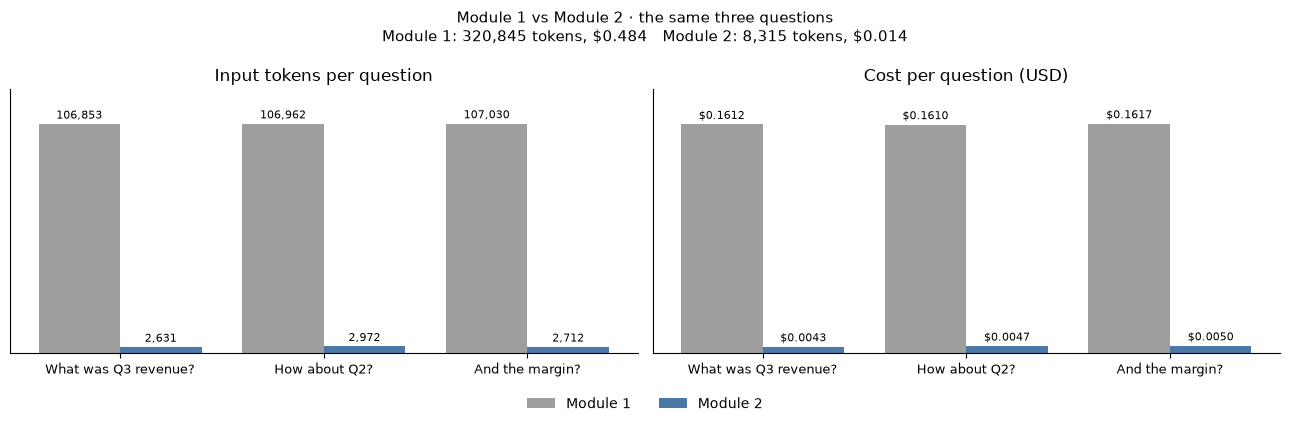

In [11]:
save_runs("module_2", runs) # Module 4 charts itself against these
if module_1:
    compare({"Module 1": module_1, "Module 2": runs}, "Module 1 vs Module 2 · the same three questions")
else:
    print("Run Module 1 first to chart against it.")
    compare({"Module 2": runs}, "Module 2 · basic RAG")

## Where a fixed pipeline breaks

Module 2 fixed the cost. Now two messages that show its limits.

In [12]:
answer("Thanks!")

› Thanks!

Retrieved top-5:
 chunk 113 0.578 SUPPLEMENTAL OPERATING DATA
 chunk 232 0.576 SUPPLEMENTAL OPERATING DATA
 chunk 212 0.575 SUPPLEMENTAL OPERATING DATA
 chunk 230 0.575 SUPPLEMENTAL OPERATING DATA
 chunk 197 0.575 SUPPLEMENTAL OPERATING DATA



The provided context does not contain information about the margin (or operating margin).

prompt_tokens=2,924 (v0: ~99,730) completion_tokens=15 latency=1.05s cost=$0.0045 (v0 input alone: $0.15)


It retrieved and paid for ~3K tokens of context to reply to "Thanks!". Nothing decides *whether* to search.

Now a comparison. Q3 is discussed in the MD&A; Q2 only appears in Appendix A, the previously reported second quarter.

In [13]:
answer("Compare Q3 and Q2 revenue.")

› Compare Q3 and Q2 revenue.

Retrieved top-5:
 chunk  11 0.697 Note 4. Segment Information → Note 5. Fair Value Measurements
 chunk 109 0.693 SUPPLEMENTAL OPERATING DATA
 chunk 145 0.691 SUPPLEMENTAL OPERATING DATA
 chunk 148 0.691 SUPPLEMENTAL OPERATING DATA
 chunk 117 0.690 SUPPLEMENTAL OPERATING DATA



Based on the provided context, total revenue for Q2 and Q3 is not explicitly provided, nor is overall company revenue listed across those periods. However, chunk 11 provides segment revenue for **Q3 2026**:

* **Cloud Services:** $2,398 million
* **Enterprise Software:** $1,226 million
* **Devices and Other:** $588 million
* **Total Q3 2026 Segment Revenue:** $4,212 million

The provided context **does not contain Q2 segment revenue** to allow for a direct segment-by-segment comparison between Q3 and Q2.

*(Note: While chunks 145, 148, and 117 provide Q2 and Q3 regional figures for specific product categories/analytics, the overall total revenue or product names for those tables are not identified in the text).*

prompt_tokens=3,009 (v0: ~99,730) completion_tokens=191 latency=2.29s cost=$0.0062 (v0 input alone: $0.15)


In [14]:
def rank_of(question: str, section_prefix: str) -> None:
    found = collection.query(query_embeddings=[embed([QUERY_PREFIX + question])[0].tolist()],
                             n_results=collection.count()) # every chunk, nearest first
    order = [int(i) for i in found["ids"][0]]
    best = min(order.index(i) for i, c in enumerate(chunks)
               if any(s.startswith(section_prefix) for s in c["sections"]))
    print(f"Best '{section_prefix}' chunk ranked #{best + 1} of {len(chunks)} (we only send the top {K}).")


rank_of("Compare Q3 and Q2 revenue.", "APPENDIX A")

Best 'APPENDIX A' chunk ranked #74 of 240 (we only send the top 5).


One query vector lands near the Q3 discussion, so the Q2 numbers never make the top 5. Fixing this means **planning two searches**, one per quarter.

| Message | What Module 2 does | What would fix it | Where |
|---|---|---|---|
| "Thanks, that helps!" | Retrieves anyway | Decide whether to search | Module 3 |
| "Compare Q3 and Q2" | One query, misses Q2 | Plan two searches | Module 3 |
| "How about Q2?" | Searches the follow-up as typed | Let the model write the search from the chat | Module 3 |
| "how'd we do lately" | Weak match | Grade, rewrite and retry | Module 4 |
| "error code E-4021" | Vector search misses it | Hybrid BM25 + vector | [opensearch-in-action](https://github.com/harshuljain13/opensearch-in-action) |

**Module 2 fixed the cost: ~100K → ~3K input tokens per question.** What it still cannot do is decide anything: it retrieves on every message, once, with the query as typed. Most fixes need the model to make decisions, and a model that decides, with tools, in a loop, is an agent. That is Module 3: `module_3_give_the_model_judgment.ipynb`.